In [1]:
!git clone https://github.com/Nightshadow7/Deep-Learning.git
%cd Deep-Learning

Cloning into 'Deep-Learning'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 36 (delta 14), reused 8 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 290.24 KiB | 7.84 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/Deep-Learning


In [2]:
!ls

eda_fusion.py			LICENSE
esc50.csv			procesador_audio.py
grafico_1_cantidad_sonidos.png	README.md
grafico_2_duracion_sonidos.png	UrbanSound8K.csv
grafico_3_cerca_vs_lejos.png


In [5]:
# 1. Descargar y descomprimir ESC-50 (~600 MB)
!echo "Descargando ESC-50..."
!wget -q --show-progress https://github.com/karoldvl/ESC-50/archive/master.zip -O esc50.zip
!unzip -q esc50.zip && mv ESC-50-master ESC-50
!echo "ESC-50 listo."

# 2. Descargar y descomprimir UrbanSound8K (~6 GB)
!echo "Descargando UrbanSound8K (tarda alrededor de 1 a 2 minutos)..."
!wget -q --show-progress https://zenodo.org/record/1203745/files/UrbanSound8K.tar.gz -O UrbanSound8K.tar.gz
!echo "Descomprimiendo UrbanSound8K..."
!tar -xzf UrbanSound8K.tar.gz
!echo "UrbanSound8K listo."

Descargando ESC-50...
esc50.zip           100%[===================>] 615.78M  21.6MB/s    in 20s     
ESC-50 listo.
Descargando UrbanSound8K (tarda alrededor de 1 a 2 minutos)...
UrbanSound8K.tar.gz 100%[===================>]   5.61G  1.88MB/s    in 44m 41s 
Descomprimiendo UrbanSound8K...
UrbanSound8K listo.


In [6]:
import pandas as pd
from procesador_audio import procesar_audio_tactico

# Selecciona automáticamente la primera sirena registrada en tu esc50.csv
esc50 = pd.read_csv("esc50.csv")
nombre_archivo = esc50[esc50["category"] == "siren"].iloc[0]["filename"]
ruta_prueba = f"ESC-50/audio/{nombre_archivo}"

# Ejecuta la prueba unitaria
tensor_prueba = procesar_audio_tactico(ruta_prueba)
print("Archivo probado:", ruta_prueba)
print("Forma del tensor listo para la CNN:", tensor_prueba.shape)

Archivo probado: ESC-50/audio/1-31482-A-42.wav
Forma del tensor listo para la CNN: (128, 173, 1)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import os
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from procesador_audio import procesar_audio_tactico

# 1. Cargar y construir rutas de UrbanSound8K
us8k = pd.read_csv("UrbanSound8K.csv")
us8k["ruta_audio"] = us8k.apply(
    lambda row: f"UrbanSound8K/audio/fold{row['fold']}/{row['slice_file_name']}", axis=1
)

# 2. Cargar y filtrar clases tácticas de ESC-50
esc50 = pd.read_csv("esc50.csv")
clases_criticas = ["siren", "glass_breaking", "car_crash"]
esc50 = esc50[esc50["category"].isin(clases_criticas)].copy()
esc50["class"] = esc50["category"]
esc50["fold"] = 0  # Fold 0 = exclusivo para entrenamiento (evita data leakage)
esc50["ruta_audio"] = esc50["filename"].apply(lambda f: f"ESC-50/audio/{f}")

# 3. Unificar metadatos y codificar etiquetas numéricas
df_total = pd.concat(
    [us8k[["ruta_audio", "class", "fold"]], esc50[["ruta_audio", "class", "fold"]]],
    ignore_index=True
)

clases_ordenadas = sorted(df_total["class"].unique())
mapa_clases = {nombre: idx for idx, nombre in enumerate(clases_ordenadas)}
df_total["label"] = df_total["class"].map(mapa_clases)

print(f"Total de audios a procesar: {len(df_total)}")
print("Mapa de clases:", mapa_clases)

# 4. Convertir todos los audios a tensores Mel (128, 173, 1)
X_lista, y_lista, folds_lista = [], [], []
errores = 0

for _, row in tqdm(df_total.iterrows(), total=len(df_total), desc="Procesando audios"):
    ruta = row["ruta_audio"]
    if os.path.exists(ruta):
        try:
            tensor = procesar_audio_tactico(ruta).astype(np.float32)
            X_lista.append(tensor)
            y_lista.append(row["label"])
            folds_lista.append(row["fold"])
        except Exception:
            errores += 1
    else:
        errores += 1

X = np.array(X_lista, dtype=np.float32)
y = np.array(y_lista, dtype=np.int64)
folds = np.array(folds_lista, dtype=np.int64)

# 5. Guardar los tensores procesados en Google Drive
carpeta_salida = "/content/drive/MyDrive/Proyecto_Acustico_Tensores"
os.makedirs(carpeta_salida, exist_ok=True)

np.save(f"{carpeta_salida}/X_mel.npy", X)
np.save(f"{carpeta_salida}/y_labels.npy", y)
np.save(f"{carpeta_salida}/folds.npy", folds)

with open(f"{carpeta_salida}/mapa_clases.json", "w") as f:
    json.dump(mapa_clases, f, indent=4)

print(f"\nProceso finalizado. Archivos guardados en: {carpeta_salida}")
print(f"Forma de X: {X.shape} | Peso en memoria: {X.nbytes / (1024**2):.1f} MB | Errores: {errores}")

Total de audios a procesar: 8812
Mapa de clases: {'air_conditioner': 0, 'car_horn': 1, 'children_playing': 2, 'dog_bark': 3, 'drilling': 4, 'engine_idling': 5, 'glass_breaking': 6, 'gun_shot': 7, 'jackhammer': 8, 'siren': 9, 'street_music': 10}


Procesando audios: 100%|██████████| 8812/8812 [05:03<00:00, 29.05it/s]



Proceso finalizado. Archivos guardados en: /content/drive/MyDrive/Proyecto_Acustico_Tensores
Forma de X: (8812, 128, 173, 1) | Peso en memoria: 744.4 MB | Errores: 0


In [1]:
!nvidia-smi

from google.colab import drive
drive.mount('/content/drive')

Tue Nov 17 14:56:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import json
import numpy as np

carpeta = "/content/drive/MyDrive/Proyecto_Acustico_Tensores"
X = np.load(f"{carpeta}/X_mel.npy")
y = np.load(f"{carpeta}/y_labels.npy")
folds = np.load(f"{carpeta}/folds.npy")

with open(f"{carpeta}/mapa_clases.json", "r") as f:
    mapa_clases = json.load(f)

num_clases = len(mapa_clases)

# División estricta por folds (cero fuga de datos)
mask_train = folds <= 8
mask_val   = folds == 9
mask_test  = folds == 10

X_train, y_train = X[mask_train], y[mask_train]
X_val, y_val     = X[mask_val], y[mask_val]
X_test, y_test   = X[mask_test], y[mask_test]

# Estandarización Z-score calculada únicamente sobre entrenamiento
media_train = np.mean(X_train)
std_train   = np.std(X_train) + 1e-8

X_train = (X_train - media_train) / std_train
X_val   = (X_val - media_train) / std_train
X_test  = (X_test - media_train) / std_train

print(f"Clases ({num_clases}): {mapa_clases}")
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Clases (11): {'air_conditioner': 0, 'car_horn': 1, 'children_playing': 2, 'dog_bark': 3, 'drilling': 4, 'engine_idling': 5, 'glass_breaking': 6, 'gun_shot': 7, 'jackhammer': 8, 'siren': 9, 'street_music': 10}
Train: (7159, 128, 173, 1) | Val: (816, 128, 173, 1) | Test: (837, 128, 173, 1)


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Función de pérdida Focal Loss para clases tácticas desbalanceadas
def sparse_focal_loss(gamma=2.0):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        y_true_oh = tf.one_hot(y_true, depth=tf.shape(y_pred)[-1])
        pt = tf.reduce_sum(y_true_oh * y_pred, axis=-1)
        focal_weight = tf.pow(1.0 - pt, gamma)
        ce = -tf.math.log(pt)
        return tf.reduce_mean(focal_weight * ce)
    return loss_fn

# Arquitectura CNN 2D para espectrogramas de Mel (128, 173, 1)
modelo = models.Sequential([
    layers.Input(shape=(128, 173, 1)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_clases, activation="softmax")
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=sparse_focal_loss(gamma=2.0),
    metrics=["accuracy"]
)

ruta_modelo = f"{carpeta}/mejor_modelo_cnn_tactico.keras"
lista_callbacks = [
    callbacks.ModelCheckpoint(ruta_modelo, monitor="val_loss", save_best_only=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1)
]

historial = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    callbacks=lista_callbacks
)

Epoch 1/40
224/224 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.3615 - loss: 1.3048
Epoch 1: val_loss improved from None to 4.89090, saving model to /content/drive/MyDrive/Proyecto_Acustico_Tensores/mejor_modelo_cnn_tactico.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Proyecto_Acustico_Tensores/mejor_modelo_cnn_tactico.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 54s 153ms/step - accuracy: 0.4538 - loss: 1.0531 - val_accuracy: 0.1520 - val_loss: 4.8909 - learning_rate: 0.0010
Epoch 2/40
223/224 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6177 - loss: 0.6903
Epoch 2: val_loss improved from 4.89090 to 3.72605, saving model to /content/drive/MyDrive/Proyecto_Acustico_Tensores/mejor_modelo_cnn_tactico.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Proyecto_Acustico_Tensores/mejor_modelo_cnn_tactico.keras
224/224 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.6564 - loss: 0.6166 - val_accuracy: 0.3260 - val_loss: 3.7260 - learning_rate: 0.0010
Epoch 3/40
2

=== REPORTE DE CLASIFICACIÓN EN TEST (FOLD 10) ===

                  precision    recall  f1-score   support

 air_conditioner     0.7614    0.6700    0.7128       100
        car_horn     1.0000    0.8485    0.9180        33
children_playing     0.6538    0.8500    0.7391       100
        dog_bark     0.7426    0.7500    0.7463       100
        drilling     0.7670    0.7900    0.7783       100
   engine_idling     0.8831    0.7312    0.8000        93
        gun_shot     0.8649    1.0000    0.9275        32
      jackhammer     0.8529    0.9062    0.8788        96
           siren     0.8769    0.6867    0.7703        83
    street_music     0.8774    0.9300    0.9029       100

        accuracy                         0.8017       837
       macro avg     0.8280    0.8163    0.8174       837
    weighted avg     0.8097    0.8017    0.8012       837



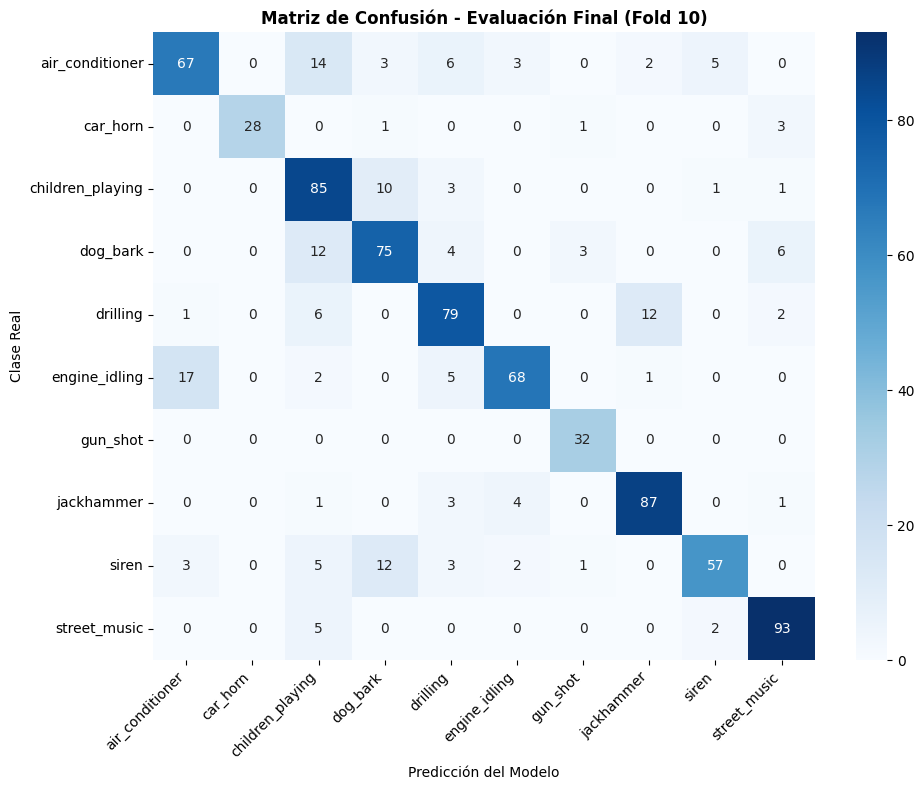

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Generar predicciones sobre el conjunto aislado de prueba (Fold 10)
probabilidades_test = modelo.predict(X_test, verbose=0)
y_pred = np.argmax(probabilidades_test, axis=1)

# 2. Recuperar los nombres de las clases presentes en el Fold 10
# (Nota: glass_breaking estuvo solo en Fold 0 de entrenamiento, por lo que no aparece en Fold 10)
idx_a_clase = {v: k for k, v in mapa_clases.items()}
clases_presentes = sorted(np.unique(np.concatenate([y_test, y_pred])))
nombres_presentes = [idx_a_clase[i] for i in clases_presentes]

# 3. Reporte de métricas tácticas (Precision, Recall y F1-Score)
print("=== REPORTE DE CLASIFICACIÓN EN TEST (FOLD 10) ===\n")
print(classification_report(y_test, y_pred, labels=clases_presentes, target_names=nombres_presentes, digits=4))

# 4. Graficar y guardar la Matriz de Confusión para las diapositivas
cm = confusion_matrix(y_test, y_pred, labels=clases_presentes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=nombres_presentes, yticklabels=nombres_presentes
)
plt.title("Matriz de Confusión - Evaluación Final (Fold 10)", fontweight="bold")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{carpeta}/matriz_confusion_test.png", dpi=150)
plt.show()